# Notebook 11 – Handling Imbalanced Data

# 1. What is Class Imbalance?


## Step 1 – Understand Concept

Class imbalance occurs when the classes in a classification dataset are not represented equally.

For example, suppose we are predicting customer churn:

- 9,000 customers did not churn
- 1,000 customers churned

Here, the Churn class represents only a small portion of the dataset.

The majority class is the class with more observations.

The minority class is the class with fewer observations.

Class imbalance is common in real-world problems such as:

- Fraud detection
- Disease detection
- Customer churn
- Spam detection
- Equipment failure
- Credit default detection


## Step 2 – Demonstrate Concept

Suppose a fraud detection dataset contains:

Normal transactions → 9,900
Fraud transactions → 100

Fraud represents only 1% of the dataset.

This is a highly imbalanced classification problem.

Although fraud is the minority class, correctly identifying fraud may be much more important than correctly identifying another normal transaction.



## Step 3 – Implement the Concept

Class
Normal    90
Fraud     10
Name: count, dtype: int64


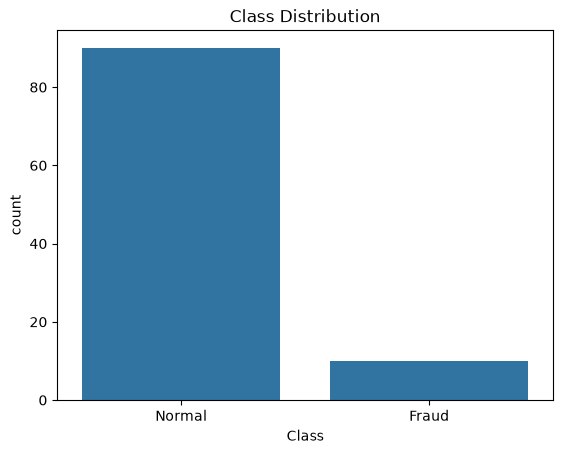

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class_data = pd.DataFrame({
    "Class": ["Normal"] * 90 + ["Fraud"] * 10
})

print(class_data["Class"].value_counts())

sns.countplot(
    data=class_data,
    x="Class"
)

plt.title("Class Distribution")
plt.show()

## Result / Observation

The dataset contains significantly more Normal observations than Fraud observations.

Therefore, the dataset is imbalanced.

The minority class should not automatically be removed because it may represent the most important class for the business problem.

# 2. Balanced vs Imbalanced Dataset


## Step 1 – Understand Concept

A balanced dataset has classes with relatively similar numbers of observations.

An imbalanced dataset has one class with significantly more observations than another.

Balanced example:

Class 0 → 5,000
Class 1 → 5,000

Imbalanced example:

Class 0 → 9,000
Class 1 → 1,000

There is no single percentage that defines imbalance for every problem.

The acceptable class distribution depends on the dataset, business problem, and consequences of classification errors.


## Step 2 – Demonstrate Concept

Consider disease detection.

Balanced:

Healthy → 500
Disease → 500

Imbalanced:

Healthy → 950
Disease → 50

The second dataset is strongly imbalanced.

Because missing a disease case may have serious consequences, we need to evaluate the model carefully rather than relying only on overall accuracy.


## Step 3 – Implement the Concept

In [2]:
balanced = pd.Series(
    ["Class 0"] * 500 + ["Class 1"] * 500
)

imbalanced = pd.Series(
    ["Class 0"] * 950 + ["Class 1"] * 50
)

print("Balanced dataset:")
print(balanced.value_counts())

print("\nImbalanced dataset:")
print(imbalanced.value_counts())

Balanced dataset:
Class 0    500
Class 1    500
Name: count, dtype: int64

Imbalanced dataset:
Class 0    950
Class 1     50
Name: count, dtype: int64


## Result / Observation

The balanced dataset contains an equal number of observations from both classes.

The imbalanced dataset contains many more Class 0 observations than Class 1 observations.

The model evaluation strategy should consider the minority class instead of focusing only on the majority class.

# 3. Why Class Imbalance is a Problem


## Step 1 – Understand Concept

Class imbalance can cause a model to become biased toward the majority class.

For example, if 95% of transactions are normal, a model can achieve 95% accuracy by predicting every transaction as normal.

However, it would detect zero fraud cases.

This means the model may have high accuracy but poor performance on the minority class.

Important evaluation metrics include:

- Precision
- Recall
- F1-score
- Confusion Matrix
- PR-AUC
- ROC-AUC, depending on the problem

The appropriate metric depends on the business cost of false positives and false negatives.



## Step 2 – Demonstrate Concept

Suppose:

Actual Normal = 950
Actual Fraud = 50

A model predicts every transaction as Normal.

Correct predictions = 950

Accuracy:

950 / 1000 = 95%

It looks good.

But:

Fraud detected = 0 / 50

So the model completely fails to identify fraud.

This demonstrates why accuracy alone can be misleading.



## Step 3 – Implement the Concept

In [3]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_true = np.array(
    [0] * 950 + [1] * 50
)

y_pred = np.zeros(1000)

print("Accuracy:")
print(accuracy_score(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        zero_division=0
    )
)

Accuracy:
0.95

Confusion Matrix:
[[950   0]
 [ 50   0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       950
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1000
   macro avg       0.47      0.50      0.49      1000
weighted avg       0.90      0.95      0.93      1000



## Result / Observation

The model achieves 95% accuracy even though it never identifies the minority class.

The confusion matrix shows:

- True Negatives = 950
- False Positives = 0
- False Negatives = 50
- True Positives = 0

Minority-class recall is 0.

Therefore, accuracy alone gives an incomplete picture of model performance on imbalanced data.

# 4. Undersampling


## Step 1 – Understand Concept

Undersampling reduces the number of observations in the majority class.

For example:

Before:
Majority → 9,000
Minority → 1,000

After undersampling:
Majority → 1,000
Minority → 1,000

This creates a more balanced training dataset.

Advantages:

- Faster training
- Smaller dataset
- Can reduce majority-class dominance

Limitations:

- Removes potentially useful majority-class information
- Can increase variance
- The selected majority observations may not represent the complete population

Undersampling should normally be applied only to the training data.



## Step 2 – Demonstrate Concept

Suppose there are:

9,000 normal transactions
1,000 fraud transactions

We can randomly select 1,000 normal transactions.

The training data becomes:

1,000 normal
1,000 fraud

The model now receives equal representation during training.

However, we have discarded 8,000 normal transactions from the training set.



## Step 3 – Implement the Concept

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.utils import resample

data = pd.DataFrame({
    "Feature": np.arange(1000),
    "Target": [0] * 900 + [1] * 100
})

train_data, test_data = train_test_split(
    data,
    test_size=0.2,
    random_state=42,
    stratify=data["Target"]
)

majority = train_data[
    train_data["Target"] == 0
]

minority = train_data[
    train_data["Target"] == 1
]

majority_downsampled = resample(
    majority,
    replace=False,
    n_samples=len(minority),
    random_state=42
)

undersampled_train = pd.concat([
    majority_downsampled,
    minority
])

print(
    undersampled_train["Target"].value_counts()
)

Target
0    80
1    80
Name: count, dtype: int64


## Result / Observation

The majority class was reduced to match the minority class.

Important:

The test data was not undersampled.

The original test distribution should normally be preserved so that evaluation reflects the real-world class distribution.

# 5. Oversampling


## Step 1 – Understand Concept

Oversampling increases the representation of the minority class.

Instead of removing majority observations, we add more minority observations to the training data.

Example:

Before:
Majority → 9,000
Minority → 1,000

After oversampling:
Majority → 9,000
Minority → 9,000

Oversampling allows the model to see more minority-class examples.

The main risk is overfitting, especially when the same minority observations are repeatedly copied.



## Step 2 – Demonstrate Concept

Suppose we have only 100 fraud examples.

Random oversampling may duplicate those examples until there are 900 fraud observations.

The model sees minority examples more frequently.

However, the duplicated observations are not new information.

This can cause the model to memorize minority examples.



## Step 3 – Implement the Concept

In [5]:
minority_upsampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

oversampled_train = pd.concat([
    majority,
    minority_upsampled
])

print(
    oversampled_train["Target"].value_counts()
)

Target
0    720
1    720
Name: count, dtype: int64


## Result / Observation

The minority class was increased until both classes had the same number of training observations.

Unlike undersampling, no majority observations were removed.

However, random oversampling may duplicate minority observations and increase overfitting risk.

# 6. Random Oversampling


## Step 1 – Understand Concept

Random Oversampling randomly duplicates observations from the minority class.

It is one of the simplest methods for handling class imbalance.

Advantages:

- Easy to implement
- Does not remove majority observations
- Works with many classification algorithms

Limitations:

- Creates duplicate observations
- Can increase overfitting
- Does not create genuinely new information
- Can increase training size



## Step 2 – Demonstrate Concept

Minority class:

A
B
C

Random oversampling might produce:

A
B
C
A
C
B
A
A

The same observations appear multiple times.

The class count becomes balanced, but no new synthetic observations were created.




## Step 3 – Implement the Concept

In [6]:
random_oversampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

print(
    random_oversampled["Target"].value_counts()
)

Target
1    720
Name: count, dtype: int64


## Result / Observation

Random oversampling increases minority-class representation by duplication.

It is simple and useful as a baseline, but synthetic methods such as SMOTE may be considered when appropriate.

# 7. Random Undersampling


## Step 1 – Understand Concept

Random Undersampling randomly removes observations from the majority class.

Advantages:

- Simple
- Fast
- Reduces training dataset size
- Can reduce majority-class dominance

Limitations:

- Useful information may be discarded
- Results can depend on which observations are removed
- May reduce model performance when the majority class contains important variation



## Step 2 – Demonstrate Concept

Suppose:

Majority = 10,000
Minority = 1,000

Random undersampling can select 1,000 majority observations.

Result:

Majority = 1,000
Minority = 1,000

The model receives balanced training data, but 9,000 majority examples are not used for that training run.


## Step 3 – Implement the Concept

In [7]:
random_undersampled = resample(
    majority,
    replace=False,
    n_samples=len(minority),
    random_state=42
)

print(
    random_undersampled["Target"].value_counts()
)

Target
0    80
Name: count, dtype: int64


## Result / Observation

Random undersampling reduces the majority class.

It can be useful when the majority class is extremely large and contains enough redundant information.

However, important majority-class patterns may be lost.

# 8. SMOTE


## Step 1 – Understand Concept

SMOTE stands for Synthetic Minority Over-sampling Technique.

Instead of simply duplicating minority observations, SMOTE creates synthetic minority examples using existing minority observations and their nearest neighbours.

The synthetic observations are generated between existing minority examples.

Advantages:

- Creates new synthetic observations
- Reduces simple duplication
- Can improve minority-class representation

Limitations:

- Synthetic points may not always be realistic
- Can introduce noise
- Can be affected by outliers
- Can be problematic when classes overlap heavily
- Not appropriate for every data type or problem

SMOTE should be applied only to the training data.



## Step 2 – Demonstrate Concept

Suppose two minority observations are:

A = (2, 4)
B = (4, 8)

SMOTE can generate a synthetic point between them, such as:

(3, 6)

The new observation is not an exact duplicate of A or B.

It is generated using the local neighbourhood of minority observations.



## Step 3 – Implement the Concept

In [18]:
%pip install imbalanced-learn

from imblearn.over_sampling import SMOTE


from imblearn.over_sampling import SMOTE

X_smote = pd.DataFrame({
    "Feature1": np.arange(100),
    "Feature2": np.arange(100) * 2
})

y_smote = np.array(
    [0] * 90 + [1] * 10
)

smote = SMOTE(
    random_state=42
)

X_resampled, y_resampled = smote.fit_resample(
    X_smote,
    y_smote
)

print("Before SMOTE:")
print(pd.Series(y_smote).value_counts())

print("\nAfter SMOTE:")
print(pd.Series(y_resampled).value_counts())

Note: you may need to restart the kernel to use updated packages.
Before SMOTE:
0    90
1    10
Name: count, dtype: int64

After SMOTE:
0    90
1    90
Name: count, dtype: int64


## Result / Observation

SMOTE increased the minority class by creating synthetic observations.

The classes are now balanced in the resampled training data.

The original test data should remain untouched.

SMOTE should be fitted only on training data to prevent information leakage.

# 9. Borderline-SMOTE

## Step 1 – Understand Concept

Borderline-SMOTE is a variation of SMOTE.

It focuses more on minority observations that are close to the decision boundary between classes.

The idea is that minority observations near the boundary may be harder for the classifier to learn.

Borderline-SMOTE creates synthetic minority examples around these difficult regions.

Advantages:

- Focuses on difficult minority observations
- Can improve learning around class boundaries

Limitations:

- May create synthetic observations in noisy or overlapping regions
- More complex than random oversampling
- Not automatically better than standard SMOTE


## Step 2 – Demonstrate Concept

Imagine two classes:

Class 0 → majority
Class 1 → minority

Some minority points are far away from Class 0.

Other minority points are close to Class 0.

The points close to the boundary are harder to classify.

Borderline-SMOTE focuses more on these boundary observations when creating synthetic samples.



## Step 3 – Implement the Concept

In [19]:
from imblearn.over_sampling import BorderlineSMOTE

borderline_smote = BorderlineSMOTE(
    random_state=42
)

X_borderline, y_borderline = (
    borderline_smote.fit_resample(
        X_smote,
        y_smote
    )
)

print("Before Borderline-SMOTE:")
print(pd.Series(y_smote).value_counts())

print("\nAfter Borderline-SMOTE:")
print(pd.Series(y_borderline).value_counts())

Before Borderline-SMOTE:
0    90
1    10
Name: count, dtype: int64

After Borderline-SMOTE:
0    90
1    90
Name: count, dtype: int64


## Result / Observation

Borderline-SMOTE generated additional minority observations while focusing on difficult minority regions.

It is useful when the decision boundary is important, but it should be validated against standard SMOTE and other approaches.

The best technique depends on the dataset and model.

# 10. Class Weights


## Step 1 – Understand Concept

Class weighting gives different importance to different classes during model training.

The minority class can receive a higher weight so that mistakes on minority observations have a larger effect on the model's learning objective.

One common option in scikit-learn is:

class_weight="balanced"

The model automatically adjusts weights based on class frequencies.

Advantages:

- No need to create synthetic observations
- No majority observations need to be removed
- Simple to use with supported algorithms

Limitations:

- Not every algorithm supports class weights
- It changes the model's learning objective rather than the dataset itself
- It may not always perform better than resampling


## Step 2 – Demonstrate Concept

Suppose:

Class 0 = 9,000
Class 1 = 1,000

Without class weights, the model may pay more attention to the majority class.

With balanced class weights, minority-class errors receive greater importance.

The original training observations remain unchanged.


## Step 3 – Implement the Concept

In [21]:
from sklearn.linear_model import LogisticRegression

weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000
)

X_weight = pd.DataFrame({
    "Feature1": np.arange(100),
    "Feature2": np.arange(100) * 2
})

y_weight = np.array(
    [0] * 90 + [1] * 10
)

weighted_model.fit(
    X_weight,
    y_weight
)

print("Model trained successfully.")
print("Class weight setting:", weighted_model.get_params()["class_weight"])

Model trained successfully.
Class weight setting: balanced


## Result / Observation

The model automatically assigned higher importance to the minority class.

No rows were duplicated or removed.

Class weighting can be a useful alternative to resampling when the selected algorithm supports it.

# 11. When to Use Each Technique


## Step 1 – Understand Concept

There is no universally best imbalance-handling technique.

The choice depends on:

- Dataset size
- Amount of imbalance
- Minority-class size
- Feature types
- Model
- Computational resources
- Overfitting risk
- Business cost of false positives and false negatives


## Step 2 – Demonstrate Concept

General guidelines:

Random Oversampling
→ Useful as a simple baseline when minority data is small.

Random Undersampling
→ Useful when the majority class is very large and contains enough redundant information.

SMOTE
→ Useful when numerical minority features can support meaningful synthetic samples.

Borderline-SMOTE
→ Useful when minority observations near class boundaries are especially difficult.

Class Weights
→ Useful when the chosen algorithm supports class weighting and we want to avoid changing the dataset.

No Resampling
→ Sometimes appropriate when the model and evaluation metrics already handle the imbalance adequately.


## Step 3 – Implement the Concept

In [11]:
comparison = pd.DataFrame({
    "Technique": [
        "Random Oversampling",
        "Random Undersampling",
        "SMOTE",
        "Borderline-SMOTE",
        "Class Weights"
    ],
    "Main_Idea": [
        "Duplicate minority observations",
        "Remove majority observations",
        "Create synthetic minority observations",
        "Create synthetic observations near minority boundaries",
        "Give minority class higher training weight"
    ]
})

print(comparison)

              Technique                                          Main_Idea
0   Random Oversampling                    Duplicate minority observations
1  Random Undersampling                       Remove majority observations
2                 SMOTE             Create synthetic minority observations
3      Borderline-SMOTE  Create synthetic observations near minority bo...
4         Class Weights         Give minority class higher training weight


## Result / Observation

Each technique solves imbalance differently.

The correct technique should be selected through validation rather than assuming that balancing the classes will automatically improve the model.

A baseline model should be compared with imbalance-handling approaches using appropriate metrics.

# 12. Why Accuracy Alone Can Be Misleading


## Step 1 – Understand Concept

Accuracy measures the percentage of all predictions that are correct.

The problem with imbalanced datasets is that the majority class can dominate this calculation.

For example:

Actual:
950 Normal
50 Fraud

A model predicts every observation as Normal.

It correctly predicts 950 out of 1,000 observations.

Accuracy = 95%.

However, the model detects:

0 out of 50 fraud cases.

Therefore, the 95% accuracy creates a misleading impression of good performance.

For imbalanced classification, we should examine metrics such as:

- Precision
- Recall
- F1-score
- Confusion Matrix
- PR-AUC
- ROC-AUC where appropriate


## Step 2 – Demonstrate Concept

Consider fraud detection.

False Negative:
A fraudulent transaction is predicted as normal.

This may cause financial loss.

False Positive:
A normal transaction is incorrectly flagged as fraud.

This may inconvenience a customer or require manual investigation.

If detecting fraud is the main business goal, recall for the fraud class may be more important than overall accuracy.

Therefore, the correct metric depends on the business consequences of errors.



## Step 3 – Implement the Concept

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

y_true = np.array(
    [0] * 950 + [1] * 50
)

# Model detects only 25 fraud cases
y_pred = np.array(
    [0] * 950 + [0] * 25 + [1] * 25
)

print("Accuracy:",
      accuracy_score(y_true, y_pred))

print("Precision:",
      precision_score(y_true, y_pred))

print("Recall:",
      recall_score(y_true, y_pred))

print("F1-score:",
      f1_score(y_true, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Accuracy: 0.975
Precision: 1.0
Recall: 0.5
F1-score: 0.6666666666666666

Confusion Matrix:
[[950   0]
 [ 25  25]]


## Result / Observation

The model can have high overall accuracy while still missing many minority-class cases.

Recall tells us how many actual positive cases were successfully identified.

Precision tells us how many predicted positive cases were actually positive.

F1-score combines precision and recall into one measure.

Therefore, accuracy should not be the only evaluation metric for an imbalanced classification problem.

# 13. Comparing Evaluation Metrics



## Step 1 – Understand Concept

Different metrics answer different questions.

Accuracy:
How many total predictions were correct?

Precision:
When the model predicts positive, how often is it correct?

Recall:
Out of all actual positive cases, how many did the model find?

F1-score:
What is the balance between precision and recall?

For highly imbalanced datasets, Precision-Recall analysis can be particularly informative because it focuses on positive-class performance.


## Step 2 – Demonstrate Concept

For disease detection:

High Recall may be preferred because missing a disease case can be costly.

For spam detection:

High Precision may be important because incorrectly marking a legitimate email as spam can be inconvenient.

Therefore, the metric should be selected based on the business problem rather than simply choosing accuracy.


## Step 3 – Implement the Concept

In [13]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

metrics = {
    "Precision": precision_score(y_true, y_pred),
    "Recall": recall_score(y_true, y_pred),
    "F1-score": f1_score(y_true, y_pred)
}

for metric, value in metrics.items():
    print(f"{metric}: {value:.3f}")

Precision: 1.000
Recall: 0.500
F1-score: 0.667


## Result / Observation

The metrics provide a more detailed view of minority-class performance than accuracy alone.

The final metric choice should depend on which type of prediction error is more costly for the business.

# 14. Correct Workflow for Imbalanced Data


## Step 1 – Understand Concept

Resampling techniques such as:

- Random Oversampling
- Random Undersampling
- SMOTE
- Borderline-SMOTE

should normally be applied only to the training data.

Correct workflow:

1. Load data.
2. Separate features and target.
3. Split into training and test data.
4. Apply resampling only to training data.
5. Train the model.
6. Evaluate on the untouched test data.

Why?

If we resample before splitting, information from the future test set can influence the training process.

This can produce overly optimistic evaluation results.



## Step 2 – Demonstrate Concept

Incorrect:

Entire dataset
→ SMOTE
→ Train/Test Split

Correct:

Entire dataset
→ Train/Test Split
→ SMOTE on Training Data
→ Train Model
→ Test on Original Test Data

The test set should represent the real distribution as closely as possible.


## Step 3 – Implement the Concept

In [22]:
import sys
print(sys.executable)

C:\Users\vaseegari\AppData\Local\Programs\Python\Python312\python.exe


In [23]:
import sys
!{sys.executable} -m pip install imbalanced-learn


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X, y = make_classification(
    n_samples=1000,
    n_features=5,
    n_informative=3,
    n_redundant=0,
    weights=[0.90, 0.10],
    random_state=42
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Before SMOTE:")
print(pd.Series(y_train).value_counts())

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("\nAfter SMOTE:")
print(pd.Series(y_train_smote).value_counts())

print("\nTest set remains unchanged:")
print(pd.Series(y_test).value_counts())

Before SMOTE:
0    715
1     85
Name: count, dtype: int64

After SMOTE:
0    715
1    715
Name: count, dtype: int64

Test set remains unchanged:
0    179
1     21
Name: count, dtype: int64


## Result / Observation

SMOTE was applied only to the training data.

The test data remained untouched and retained its original class distribution.

This is the correct approach because the test set should represent unseen real-world data.

In a complete ML pipeline, resampling should also be placed inside the training pipeline so that cross-validation does not leak information between folds.

# 15. SMOTE with a Machine Learning Pipeline



## Step 1 – Understand Concept

When using cross-validation, SMOTE should be performed separately inside each training fold.

The imbalanced-learn Pipeline can help ensure that resampling happens during model fitting and does not affect validation folds before training.

A typical workflow is:

Training data
→ Scaling / preprocessing
→ SMOTE
→ Model

The exact order depends on the data and preprocessing requirements.

The important principle is that learned preprocessing and resampling should not use validation or test information.



## Step 2 – Demonstrate Concept

Instead of:

SMOTE on the complete dataset
→ Cross-validation

Use:

Cross-validation
→ For each training fold:
   Preprocess
   → SMOTE
   → Train model
→ Evaluate on validation fold

This prevents information from the validation fold from influencing synthetic sample generation.



## Step 3 – Implement the Concept

In [25]:
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

smote_pipeline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000))
])

smote_pipeline.fit(
    X_train,
    y_train
)

predictions = smote_pipeline.predict(
    X_test
)

print(
    classification_report(
        y_test,
        predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.99      0.96      0.97       179
           1       0.70      0.90      0.79        21

    accuracy                           0.95       200
   macro avg       0.85      0.93      0.88       200
weighted avg       0.96      0.95      0.95       200



## Result / Observation

The pipeline keeps preprocessing, SMOTE, and model training together.

SMOTE is applied during fitting rather than being applied to the entire dataset before splitting.

The untouched test data is used only for final evaluation.

# 16. Final Decision Guide


## Step 1 – Understand Concept

The best imbalance technique depends on the problem.

There is no universal rule such as "always use SMOTE."

We should first establish:

- How severe the imbalance is.
- How many minority observations are available.
- Whether features are suitable for synthetic sampling.
- Whether the majority class contains redundant information.
- Which errors are more costly.
- Which algorithms are being used.
- Which evaluation metric matters.


## Step 2 – Demonstrate Concept

Example decision process:

Small minority + enough meaningful numerical features
→ Consider SMOTE.

Minority points near difficult boundaries
→ Consider Borderline-SMOTE.

Extremely large majority class
→ Consider Random Undersampling.

Small minority class and simple baseline needed
→ Consider Random Oversampling.

Algorithm supports class weighting
→ Consider Class Weights.

Already good minority-class performance
→ Resampling may not be necessary.

Always compare alternatives using appropriate validation metrics.



## Step 3 – Implement the Concept

In [16]:
decision_table = pd.DataFrame({
    "Technique": [
        "Random Oversampling",
        "Random Undersampling",
        "SMOTE",
        "Borderline-SMOTE",
        "Class Weights"
    ],
    "Use_When": [
        "Minority class is small and duplication is acceptable",
        "Majority class is very large",
        "Numerical features support meaningful synthetic samples",
        "Minority boundary cases need more attention",
        "Model supports class weighting"
    ],
    "Main_Risk": [
        "Overfitting from duplicates",
        "Loss of majority information",
        "Unrealistic synthetic samples",
        "Synthetic noise near overlapping boundaries",
        "May not improve every model"
    ]
})

print(decision_table)

              Technique                                           Use_When  \
0   Random Oversampling  Minority class is small and duplication is acc...   
1  Random Undersampling                       Majority class is very large   
2                 SMOTE  Numerical features support meaningful syntheti...   
3      Borderline-SMOTE        Minority boundary cases need more attention   
4         Class Weights                     Model supports class weighting   

                                     Main_Risk  
0                  Overfitting from duplicates  
1                 Loss of majority information  
2                Unrealistic synthetic samples  
3  Synthetic noise near overlapping boundaries  
4                  May not improve every model  


## Result / Observation

Each method has advantages and limitations.

The final choice should be based on validation performance, data characteristics, model behaviour, and business requirements.

A good baseline without resampling should also be compared with the resampling or class-weighted approaches.

# Final Summary – Handling Imbalanced Data

In this notebook, we learned:

1. What is Class Imbalance?
2. Balanced vs Imbalanced Dataset
3. Why Class Imbalance is a Problem
4. Undersampling
5. Oversampling
6. Random Oversampling
7. Random Undersampling
8. SMOTE
9. Borderline-SMOTE
10. Class Weights
11. When to Use Each Technique
12. Why Accuracy Alone Can Be Misleading
13. Evaluation Metrics
14. Correct Resampling Workflow
15. SMOTE with Machine Learning Pipeline

## Key Concepts

### Random Oversampling
Duplicates minority observations.

### Random Undersampling
Removes majority observations.

### SMOTE
Creates synthetic minority observations using neighbouring minority samples.

### Borderline-SMOTE
Focuses synthetic generation around difficult minority-class boundary regions.

### Class Weights
Changes the importance given to each class during model training without changing the dataset.

## Most Important Rule

Never apply SMOTE or other resampling techniques to the complete dataset before train/test splitting.

Correct:

Split → Resample Training Data → Train → Evaluate on Untouched Test Data

## Accuracy Warning

Accuracy can be misleading when classes are highly imbalanced.

A model can achieve 95% accuracy simply by predicting the majority class every time while completely failing to detect the minority class.

Therefore, also examine:

- Precision
- Recall
- F1-score
- Confusion Matrix
- PR-AUC / ROC-AUC where appropriate

The correct metric depends on the business cost of false positives and false negatives.